In [21]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.callbacks import ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils.class_weight import compute_class_weight
from tqdm import tqdm

In [7]:
TRAIN_GROUNDTRUTH_PATH = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_GroundTruth.csv"
# TEST_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/ham10000/HAM10000_Test_GroundTruth_Updated.csv"
# TEST2_GROUNDTRUTH_PATH = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_GroundTruth.csv"

TRAIN_IMAGE_DIR = "/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Input"
# TEST_IMAGE_DIR = "/teamspace/studios/this_studio/ham10000/HAM10000_images_part_12"
# TEST2_IMAGE_DIR = "/teamspace/studios/this_studio/data/test/ISIC_2019_Test_Input"

IMG_SIZE = (456, 456)
BATCH_SIZE = 32
EPOCHS = 20
LABELS = ['MEL', 'NV', 'BCC', 'AK', 'BKL', 'DF', 'VASC', 'SCC']

In [8]:
def read_ds(gnd_path):
    df = pd.read_csv(gnd_path)
    return df

def get_image_paths_and_labels(df, image_dir):
    image_paths = [os.path.join(image_dir, row['image'] + '.jpg') for _, row in df.iterrows()]
    labels = df[LABELS].values  # One-hot labels
    return image_paths, labels

train_groundtruth = read_ds(TRAIN_GROUNDTRUTH_PATH)
# test_groundtruth = read_ds(TEST_GROUNDTRUTH_PATH)
# test_groundtruth_2 = read_ds(TEST2_GROUNDTRUTH_PATH)

train_paths, train_labels = get_image_paths_and_labels(train_groundtruth, TRAIN_IMAGE_DIR)
# test_paths, test_labels = get_image_paths_and_labels(test_groundtruth, TEST_IMAGE_DIR)
# test_paths_2, test_labels_2 = get_image_paths_and_labels(test_groundtruth_2, TEST2_IMAGE_DIR)

In [9]:
from sklearn.model_selection import train_test_split

train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    train_paths, train_labels, test_size=0.2, stratify=train_labels, random_state=42
)

val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.5, stratify=temp_labels, random_state=42
)

In [10]:
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def preprocess_and_augment(file_path, label):
    img, label = load_image(file_path, label)
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.random_brightness(img, max_delta=0.2)
    img = tf.image.random_contrast(img, lower=0.8, upper=1.2)
    return img, label

train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


2025-05-08 20:37:27.998880: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-05-08 20:37:27.999100: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 32.00 GB
2025-05-08 20:37:27.999106: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 10.67 GB
I0000 00:00:1746725847.999859 18710102 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1746725847.999929 18710102 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [11]:
def build_model():
    base_model = EfficientNetV2S(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
    

    base_model.trainable = True
    for layer in base_model.layers[:int(len(base_model.layers) * 0.7)]:
        layer.trainable = False 

    inputs = tf.keras.Input(shape=(*IMG_SIZE, 3))
    x = base_model(inputs, training=False)

    x = layers.GlobalAveragePooling2D()(x) 


    x = layers.Dense(2048, activation="mish")(x)  
    x = layers.Dropout(0.4)(x)  
    x = layers.LayerNormalization()(x)  

    x = layers.Dense(1024, activation="mish")(x)
    x = layers.Dropout(0.3)(x)

    x = layers.Dense(512, activation="mish")(x)
    x = layers.Dropout(0.2)(x)

    se = layers.Lambda(lambda t: tf.expand_dims(t, axis=-1))(x) 
    se = layers.GlobalAveragePooling1D()(se)
    se = layers.Dense(64, activation="relu")(se)
    se = layers.Dense(512, activation="sigmoid")(se)
    x = layers.Multiply()([x, se])

    outputs = layers.Dense(len(LABELS), activation="softmax")(x)
    model = models.Model(inputs, outputs)

    optimizer = tf.keras.optimizers.Adam(learning_rate=1e-4)

    model.compile(
        optimizer=optimizer, 
        loss="categorical_crossentropy",  
        metrics=[
            "accuracy",
            tf.keras.metrics.AUC(name="auc"),
            tf.keras.metrics.Precision(name="precision"), 
            tf.keras.metrics.Recall(name="recall")
        ]
)


    return model

model = build_model()


In [12]:
train_labels_argmax = np.argmax(train_labels, axis=1)
class_weights = compute_class_weight(class_weight="balanced", classes=np.arange(len(LABELS)), y=train_labels_argmax)
class_weights_dict = {i: weight for i, weight in enumerate(class_weights)}

In [23]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 456, 456,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetv2-s    │ (None, 15, 15,    │ 20,331,360 │ input_layer_3[0]… │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetv2-s… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 2048)      │  2,623,488 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 2048)      │          0 │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 2048)      │      4,096 │ dropout_3[0][0]   │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1024)      │  2,098,176 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 1024)      │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_8 (Dense)     │ (None, 512)       │    524,800 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 512)       │          0 │ dense_8[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 512, 1)    │          0 │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1)         │          0 │ lambda_1[0][0]    │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 64)        │        128 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 512)       │     33,280 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multiply_1          │ (None, 512)       │          0 │ dropout_5[0][0],  │
│ (Multiply)          │                   │            │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 8)         │      4,104 │ multiply_1[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 25,619,432 (97.73 MB)

 Trainable params: 15,669,512 (59.77 MB)

 Non-trainable params: 9,949,920 (37.96 MB)

In [25]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


633/634 ━━━━━━━━━━━━━━━━━━━━ 0s 336ms/step - accuracy: 0.4586 - auc: 0.8453 - loss: 1.3991 - precision: 0.6027 - recall: 0.2760

2025-03-17 12:30:24.026557: I external/local_xla/xla/stream_executor/cuda/cuda_asm_compiler.cc:397] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_31732', 208 bytes spill stores, 332 bytes spill loads



634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 407ms/step - accuracy: 0.4587 - auc: 0.8453 - loss: 1.3991 - precision: 0.6028 - recall: 0.2761
Epoch 1: val_accuracy improved from -inf to 0.58389, saving model to efficientnet-v2-m-onehot-deep-split_baserun.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 300s 464ms/step - accuracy: 0.4587 - auc: 0.8453 - loss: 1.3990 - precision: 0.6028 - recall: 0.2762 - val_accuracy: 0.5839 - val_auc: 0.9139 - val_loss: 1.1325 - val_precision: 0.6410 - val_recall: 0.5124 - learning_rate: 1.0000e-04
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 342ms/step - accuracy: 0.5712 - auc: 0.9074 - loss: 0.9981 - precision: 0.6569 - recall: 0.4648
Epoch 2: val_accuracy improved from 0.58389 to 0.64114, saving model to efficientnet-v2-m-onehot-deep-split_baserun.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 238s 366ms/step - accuracy: 0.5713 - auc: 0.9074 - loss: 0.9981 - precision: 0.6569 - recall: 0.4649 - val_accuracy: 0.6411 - val_auc: 0.9322 - val_loss: 1.0145 - val_precision: 0.6888 - val_recall: 0

In [27]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history2 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20


634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 337ms/step - accuracy: 0.9015 - auc: 0.9940 - loss: 0.1371 - precision: 0.9068 - recall: 0.8953
Epoch 1: val_accuracy improved from -inf to 0.82432, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 235s 361ms/step - accuracy: 0.9015 - auc: 0.9940 - loss: 0.1371 - precision: 0.9068 - recall: 0.8953 - val_accuracy: 0.8243 - val_auc: 0.9691 - val_loss: 0.6595 - val_precision: 0.8308 - val_recall: 0.8220 - learning_rate: 2.5000e-05
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 332ms/step - accuracy: 0.9080 - auc: 0.9940 - loss: 0.1328 - precision: 0.9144 - recall: 0.9013
Epoch 2: val_accuracy improved from 0.82432 to 0.82906, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 231s 356ms/step - accuracy: 0.9080 - auc: 0.9940 - loss: 0.1328 - precision: 0.9144 - recall: 0.9013 - val_accuracy: 0.8291 - val_auc: 0.9687 - val_loss: 0.6575 - val_precision: 0.8336 - val_recal

In [28]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot-deep-split_baserun_2.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", 
                                                    factor=0.5, 
                                                    patience=3, 
                                                    min_lr=1e-6, 
                                                    verbose=1)
                                                    
history3 = model.fit(train_dataset, validation_data=val_dataset, epochs=EPOCHS, callbacks=[checkpoint, lr_scheduler],
                    class_weight=class_weights_dict)

Epoch 1/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 334ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387
Epoch 1: val_accuracy improved from -inf to 0.83853, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 233s 359ms/step - accuracy: 0.9421 - auc: 0.9978 - loss: 0.0734 - precision: 0.9478 - recall: 0.9387 - val_accuracy: 0.8385 - val_auc: 0.9683 - val_loss: 0.6954 - val_precision: 0.8415 - val_recall: 0.8362 - learning_rate: 1.0000e-06
Epoch 2/20
634/634 ━━━━━━━━━━━━━━━━━━━━ 0s 333ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372
Epoch 2: val_accuracy improved from 0.83853 to 0.84366, saving model to efficientnet-v2-m-onehot-deep-split_baserun_2.keras
634/634 ━━━━━━━━━━━━━━━━━━━━ 232s 358ms/step - accuracy: 0.9399 - auc: 0.9973 - loss: 0.0809 - precision: 0.9441 - recall: 0.9372 - val_accuracy: 0.8437 - val_auc: 0.9700 - val_loss: 0.6858 - val_precision: 0.8460 

58/80 ━━━━━━━━━━━━━━━━━━━━ 3s 166ms/step - accuracy: 0.8440 - auc: 0.9662 - loss: 0.7485 - precision: 0.8475 - recall: 0.8404

80/80 ━━━━━━━━━━━━━━━━━━━━ 23s 290ms/step - accuracy: 0.8459 - auc: 0.9671 - loss: 0.7300 - precision: 0.8493 - recall: 0.8426


2025-03-17 16:26:08.087515: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


80/80 ━━━━━━━━━━━━━━━━━━━━ 31s 278ms/step
              precision    recall  f1-score   support

         MEL       0.74      0.78      0.76       452
          NV       0.92      0.89      0.90      1288
         BCC       0.87      0.93      0.90       333
          AK       0.69      0.76      0.72        86
         BKL       0.79      0.76      0.77       263
          DF       0.75      0.75      0.75        24
        VASC       0.85      0.88      0.86        25
         SCC       0.73      0.70      0.72        63

    accuracy                           0.85      2534
   macro avg       0.79      0.81      0.80      2534
weighted avg       0.85      0.85      0.85      2534



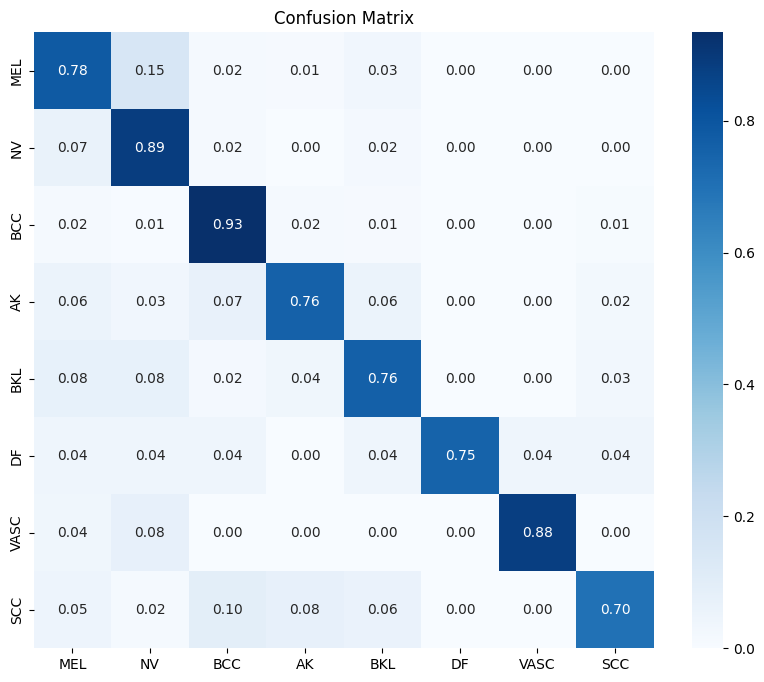

In [29]:
result = model.evaluate(test_dataset)
y_true = np.argmax(np.concatenate([y.numpy() for _, y in test_dataset]), axis=1)
y_pred = np.argmax(model.predict(test_dataset), axis=1)

print(classification_report(y_true, y_pred, target_names=LABELS))

conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
plt.title("Confusion Matrix")
plt.show()

# Fine-tuning

In [18]:
tf.compat.v1.enable_eager_execution()
model = tf.keras.models.load_model('/teamspace/studios/this_studio/models/weights/efficientnet-v2-m-onehot_baserun.keras')

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 1308 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [15]:
model.evaluate(test_dataset_2)

258/258 ━━━━━━━━━━━━━━━━━━━━ 580s 2s/step - accuracy: 0.5873 - loss: 0.8531 - precision: 0.6827 - recall: 0.5625


[0.8416513204574585,
 0.4922311305999756,
 0.5843790769577026,
 0.5039573311805725]

In [20]:
for layer in model.layers:
     if layer.name == 'efficientnetv2-m':
         layer.trainable = True
         for l in layer.layers[:-200]:
              l.trainable = False
         for l in layer.layers[-200:]:
              l.trainable = True
     if layer.name == 'batch_normalization_1':
         layer.trainable = False
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 456, 456, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-m (Functional)   │ (None, 15, 15, 1280)   │    53,150,388 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1024)           │     1,311,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         8,200 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162,835,126 (621.17 MB)

 Trainable params: 31,530,196 (120.28 MB)

 Non-trainable params: 22,944,232 (87.53 MB)

 Optimizer params: 108,360,698 (413.36 MB)

In [21]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20


792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.6119 - loss: 0.9054 - precision: 0.6894 - recall: 0.5100
Epoch 1: val_accuracy improved from -inf to 0.56555, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2619s 3s/step - accuracy: 0.6118 - loss: 0.9058 - precision: 0.6894 - recall: 0.5099 - val_accuracy: 0.5656 - val_loss: 1.2173 - val_precision: 0.6631 - val_recall: 0.4442
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6558 - loss: 0.6761 - precision: 0.7386 - recall: 0.5603
Epoch 2: val_accuracy improved from 0.56555 to 0.62566, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2177s 3s/step - accuracy: 0.6558 - loss: 0.6764 - precision: 0.7386 - recall: 0.5603 - val_accuracy: 0.6257 - val_loss: 1.0137 - val_precision: 0.6772 - val_recall: 0.5494
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.6923 - loss: 0.5476 - precision: 0.7503 - recall: 0.6250
Epoch 3: val_accur

KeyboardInterrupt: 

In [ ]:
checkpoint = ModelCheckpoint("efficientnet-v2-m-onehot_finetuning.keras", monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
history = model.fit(train_dataset, validation_data=test_dataset_2, epochs=EPOCHS, callbacks=[checkpoint],
                    class_weight=class_weights_dict)

Epoch 1/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7569 - loss: 0.3798 - precision: 0.7922 - recall: 0.7203
Epoch 1: val_accuracy improved from -inf to 0.50522, saving model to efficientnet-v2-m-onehot_finetuning.keras
792/792 ━━━━━━━━━━━━━━━━━━━━ 2074s 3s/step - accuracy: 0.7570 - loss: 0.3799 - precision: 0.7922 - recall: 0.7203 - val_accuracy: 0.5052 - val_loss: 0.9712 - val_precision: 0.5086 - val_recall: 0.6099
Epoch 2/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7983 - recall: 0.7368
Epoch 2: val_accuracy did not improve from 0.50522
792/792 ━━━━━━━━━━━━━━━━━━━━ 2025s 3s/step - accuracy: 0.7700 - loss: 0.3524 - precision: 0.7984 - recall: 0.7369 - val_accuracy: 0.4942 - val_loss: 1.1084 - val_precision: 0.4868 - val_recall: 0.5870
Epoch 3/20
792/792 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.7780 - loss: 0.3390 - precision: 0.8038 - recall: 0.7458
Epoch 3: val_accuracy improved from 0.50522 to 0.51238, saving model t

In [40]:
model.save('efficientnet-v2-m-onehot_baserun.keras')

In [11]:
import pandas as pd

metadata = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/ISIC_2020_Dataset/ISIC_2020_Train_Metadata.csv')
metadata_2019 = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Metadata.csv')
# Filter out rows where the diagnosis is 'unknown'
metadata_filtered = metadata[metadata['diagnosis'] == 'melanoma']

# Check if the image names in 'metadata' are not in 'metadata_2019'
metadata_filtered = metadata_filtered[~metadata_filtered['image_name'].isin(metadata_2019['image'])]

# Show the result
print(metadata_filtered)

         image_name  patient_id   lesion_id     sex  age_approx  \
91     ISIC_0149568  IP_0962375  IL_6540984  female        55.0   
235    ISIC_0188432  IP_0135517  IL_7870569  female        50.0   
314    ISIC_0207268  IP_7735373  IL_1066532    male        55.0   
399    ISIC_0232101  IP_8349964  IL_8939481    male        65.0   
459    ISIC_0247330  IP_3232631  IL_3206110  female        65.0   
...             ...         ...         ...     ...         ...   
32969  ISIC_9955163  IP_7507212  IL_4873145    male        55.0   
33000  ISIC_9963177  IP_1165806  IL_0973502    male        70.0   
33014  ISIC_9967383  IP_7887363  IL_2267077    male        60.0   
33050  ISIC_9978107  IP_2860540  IL_8465436    male        65.0   
33117  ISIC_9998682  IP_2516168  IL_1802809    male        60.0   

      anatom_site_general_challenge diagnosis benign_malignant  target  
91                  upper extremity  melanoma        malignant       1  
235                 upper extremity  melanoma    

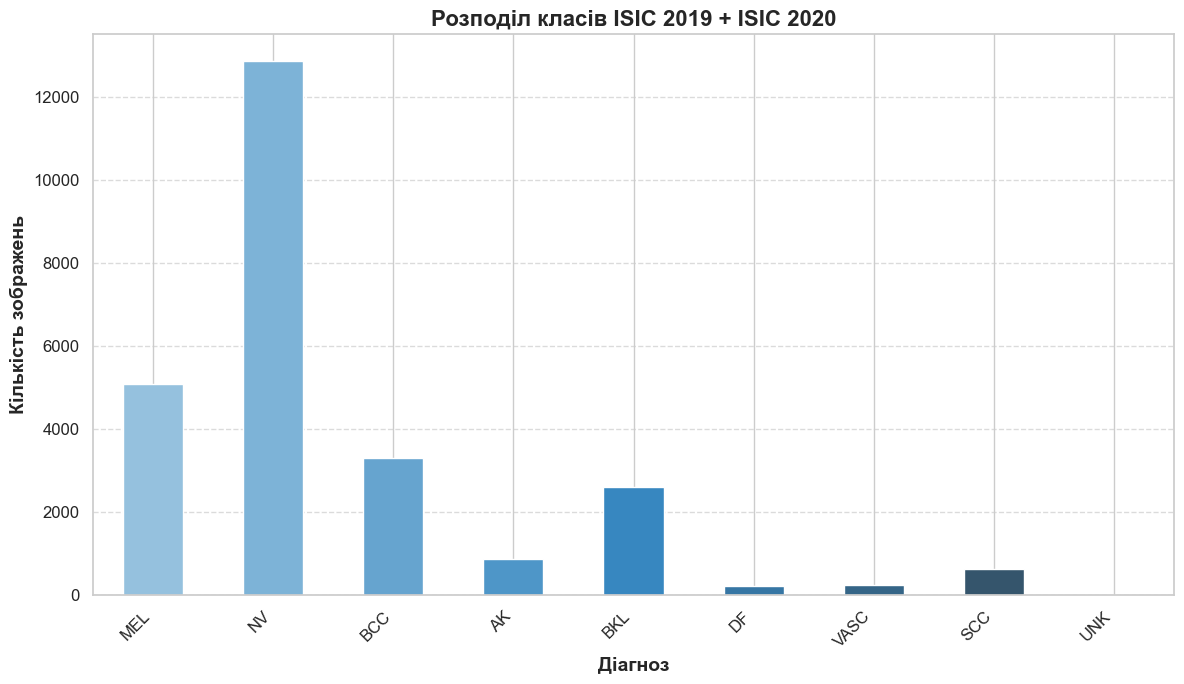

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the metadata for ISIC 2019
metadata_2019 = pd.read_csv('/Users/mac/Development/diploma/skin-mutation-detection/data/train/ISIC_2019_Training_Groundtruth.csv')

# Sum up the values for each class (ignoring the 'image' column)
class_counts = metadata_2019.drop(columns=['image']).sum()

# Add 584 to the 'MEL' class count as per your request
class_counts['MEL'] += 584

# Set a modern Seaborn style
sns.set(style="whitegrid")

# Create the plot with custom colors from Seaborn's palette
plt.figure(figsize=(12, 7))
ax = class_counts.plot(kind='bar', color=sns.color_palette("Blues_d", len(class_counts)))

# Adding a title and labels with modern fonts
plt.title('Розподіл класів ISIC 2019 + ISIC 2020', fontsize=16, fontweight='bold')
plt.xlabel('Діагноз', fontsize=14, fontweight='bold')
plt.ylabel('Кількість зображень', fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)

# Add a grid for better readability on the y-axis
plt.grid(True, axis='y', linestyle='--', alpha=0.7)

# Tight layout to make sure labels don't get cut off
plt.tight_layout()

# Show the plot
plt.show()


In [36]:
def plot_history_ukr(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label=f'Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label=f'Валідаційний набір')
            plt.title(f'{metric_labels[metric]} протягом епох')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()
# plot_history_ukr(history2.history)


In [14]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()

In [19]:
def confusion(model, ds):
  tf.keras.config.enable_unsafe_deserialization()
  # model.load_weights(f"{MODEL_NAME}_softmask_baserun_2.keras")
  # result = model.evaluate(ds)
  # print(result)
  y_true = np.argmax(np.concatenate([y.numpy() for _, y in tqdm(ds)]), axis=1)
  y_pred = np.argmax(model.predict(ds), axis=1)

  print(classification_report(y_true, y_pred, target_names=LABELS))

  conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
  plt.figure(figsize=(10, 8))
  sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
  plt.title("Confusion Matrix")
  plt.show()

def test_model(model, history):
  print(history.history)
  plot_history(history.history)
  plot_history_ukr(history.history)
  train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
  train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

  for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    print(f"#####  {label}  #####")
    confusion(model, dataset)


In [39]:
model = build_model()
model.load_weights("/Users/mac/Development/diploma/skin-mutation-detection/models/weights/efficientnetv2-s-onehot-deep-unified_softmask_baserun_2_no_segm.keras")

/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


/Users/mac/Library/Caches/pypoetry/virtualenvs/diploma-JhBIondL-py3.11/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:757: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 296 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


#####  train  #####


100%|██████████| 634/634 [03:27<00:00,  3.06it/s]


634/634 ━━━━━━━━━━━━━━━━━━━━ 435s 674ms/step
              precision    recall  f1-score   support

         MEL       0.57      0.46      0.51      3618
          NV       0.83      0.64      0.72     10300
         BCC       0.56      0.50      0.53      2658
          AK       0.42      0.23      0.30       694
         BKL       0.33      0.71      0.45      2099
          DF       0.28      0.24      0.26       191
        VASC       0.09      0.85      0.16       202
         SCC       0.90      0.06      0.11       502

    accuracy                           0.56     20264
   macro avg       0.50      0.46      0.38     20264
weighted avg       0.67      0.56      0.59     20264



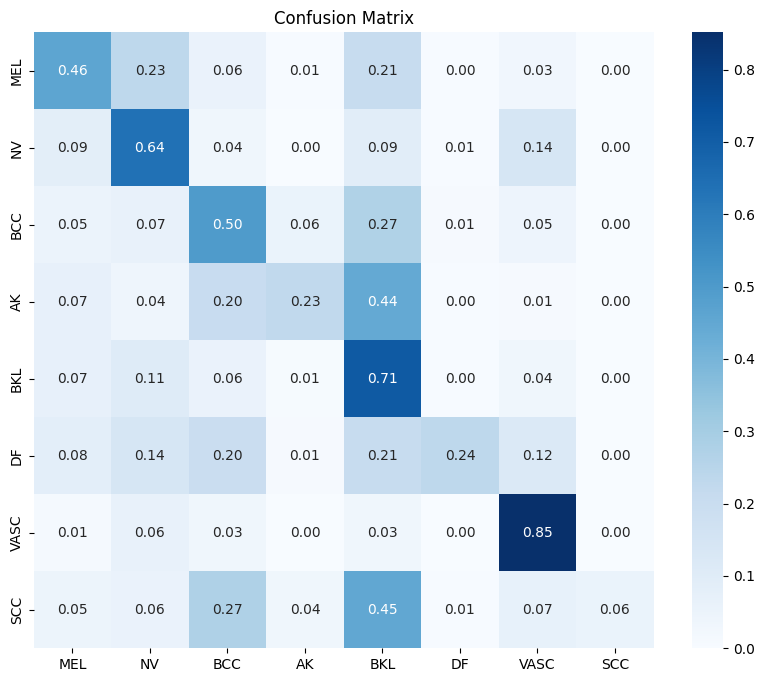

#####  val  #####


100%|██████████| 80/80 [00:02<00:00, 30.82it/s]


80/80 ━━━━━━━━━━━━━━━━━━━━ 56s 699ms/step
              precision    recall  f1-score   support

         MEL       0.53      0.48      0.51       452
          NV       0.81      0.61      0.70      1287
         BCC       0.54      0.48      0.51       332
          AK       0.45      0.15      0.22        87
         BKL       0.30      0.65      0.41       262
          DF       0.11      0.08      0.10        24
        VASC       0.07      0.65      0.12        26
         SCC       0.75      0.05      0.09        63

    accuracy                           0.54      2533
   macro avg       0.45      0.39      0.33      2533
weighted avg       0.64      0.54      0.57      2533



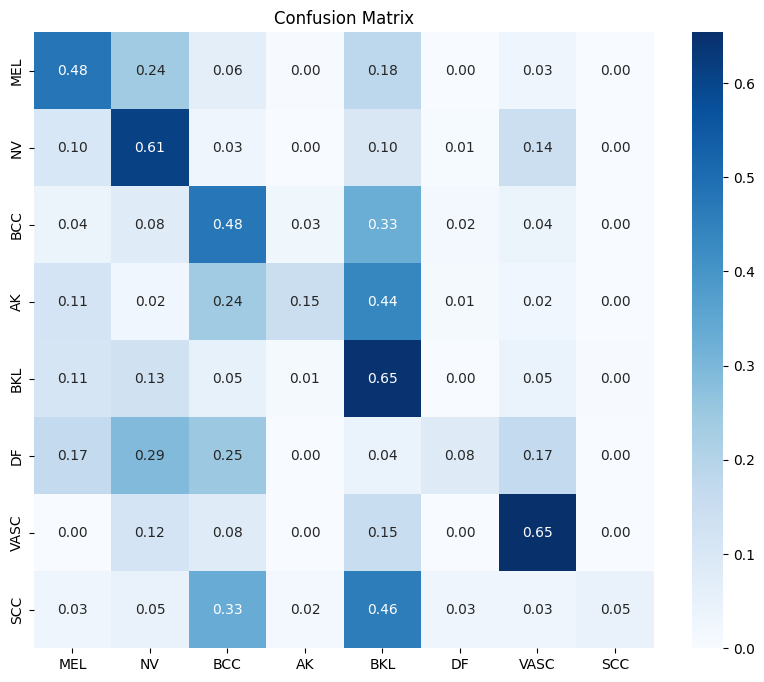

#####  test  #####


100%|██████████| 80/80 [00:03<00:00, 26.29it/s]


80/80 ━━━━━━━━━━━━━━━━━━━━ 55s 686ms/step
              precision    recall  f1-score   support

         MEL       0.54      0.47      0.50       452
          NV       0.81      0.63      0.71      1288
         BCC       0.57      0.47      0.52       333
          AK       0.36      0.10      0.16        86
         BKL       0.31      0.67      0.42       263
          DF       0.09      0.08      0.09        24
        VASC       0.07      0.64      0.12        25
         SCC       0.50      0.02      0.03        63

    accuracy                           0.55      2534
   macro avg       0.40      0.39      0.32      2534
weighted avg       0.64      0.55      0.57      2534



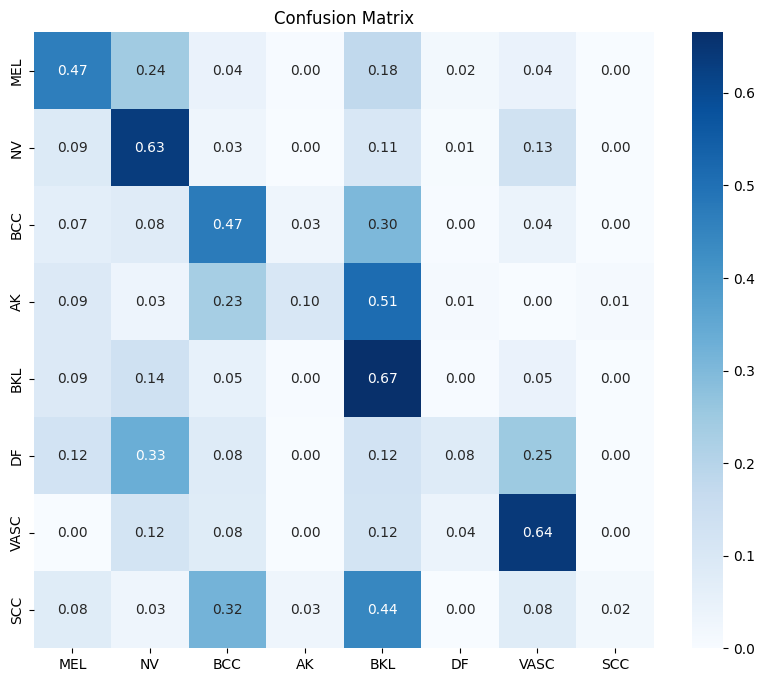

In [23]:
train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    print(f"#####  {label}  #####")
    confusion(model, dataset)

In [28]:
history = {
    "accuracy": [
        0.4587,
        0.5713,
        0.6424,
        0.6541,
        0.7046,
        0.7213,
        0.7428,
        0.7477,
        0.7776,
        0.7927,
        0.8052,
        0.8273,
        0.8467,
        0.8470,
        0.8574,
        0.8694,
        0.8778,
        0.8751,
        0.8835,
        0.8849
    ],
    "auc": [
        0.8453,
        0.9074,
        0.9342,
        0.9393,
        0.9533,
        0.9595,
        0.9653,
        0.9662,
        0.9727,
        0.9765,
        0.9781,
        0.9831,
        0.9866,
        0.9862,
        0.9883,
        0.9891,
        0.9901,
        0.9906,
        0.9922,
        0.9913
    ],
    "loss": [
        1.3990,
        0.9981,
        0.8065,
        0.7296,
        0.6398,
        0.5629,
        0.5002,
        0.4697,
        0.4011,
        0.3617,
        0.3554,
        0.2978,
        0.2371,
        0.2380,
        0.2219,
        0.2018,
        0.1929,
        0.1911,
        0.1805,
        0.1683
    ],
    "precision": [
        0.6028,
        0.6569,
        0.7140,
        0.7129,
        0.7520,
        0.7646,
        0.7764,
        0.7824,
        0.8031,
        0.8184,
        0.8284,
        0.8482,
        0.8641,
        0.8658,
        0.8706,
        0.8819,
        0.8888,
        0.8861,
        0.8932,
        0.8960
    ],
    "recall": [
        0.2762,
        0.4649,
        0.5654,
        0.5930,
        0.6518,
        0.6769,
        0.7054,
        0.7144,
        0.7484,
        0.7680,
        0.7837,
        0.8070,
        0.8308,
        0.8306,
        0.8433,
        0.8580,
        0.8668,
        0.8646,
        0.8754,
        0.8740
    ],
    "val_accuracy": [
        0.5839,
        0.6411,
        0.6605,
        0.6629,
        0.6956,
        0.7114,
        0.7189,
        0.7659,
        0.7576,
        0.7477,
        0.7710,
        0.7904,
        0.7951,
        0.7994,
        0.8089,
        0.8097,
        0.8180,
        0.8188,
        0.8085,
        0.8283
    ],
    "val_auc": [
        0.9139,
        0.9322,
        0.9397,
        0.9413,
        0.9516,
        0.9519,
        0.9461,
        0.9634,
        0.9618,
        0.9572,
        0.9637,
        0.9671,
        0.9679,
        0.9678,
        0.9677,
        0.9687,
        0.9708,
        0.9686,
        0.9635,
        0.9698
    ],
    "val_loss": [
        1.1325,
        1.0145,
        0.9597,
        0.9619,
        0.8533,
        0.8666,
        0.9089,
        0.7136,
        0.7530,
        0.8129,
        0.7344,
        0.6726,
        0.6654,
        0.6750,
        0.6675,
        0.6599,
        0.6640,
        0.6762,
        0.7424,
        0.6353
    ],
    "val_precision": [
        0.6410,
        0.6888,
        0.6972,
        0.6936,
        0.7293,
        0.7333,
        0.7435,
        0.7836,
        0.7793,
        0.7658,
        0.7893,
        0.8024,
        0.8046,
        0.8096,
        0.8214,
        0.8191,
        0.8253,
        0.8253,
        0.8171,
        0.8337
    ],
    "val_recall": [
        0.5124,
        0.5926,
        0.6198,
        0.6344,
        0.6711,
        0.6881,
        0.6956,
        0.7462,
        0.7430,
        0.7383,
        0.7600,
        0.7805,
        0.7868,
        0.7923,
        0.7991,
        0.8042,
        0.8113,
        0.8129,
        0.8026,
        0.8235
    ],
    "learning_rate": [
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        1.0e-04,
        5.0e-05,
        5.0e-05,
        5.0e-05,
        5.0e-05,
        5.0e-05,
        5.0e-05,
        5.0e-05,
        5.0e-05,
        2.5e-05,
        2.5e-05
    ]
}

In [24]:
def plot_history_ukr(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Точність',
        'loss': 'Втрата',
        'auc': 'Площа під кривою (AUC)',
        'precision': 'Влучність',
        'recall': 'Повнота'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label=f'Навчальний набір')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label=f'Валідаційний набір')
            plt.title(f'{metric_labels[metric]} протягом епох')
            plt.xlabel('Епохи')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()
# plot_history_ukr(history2.history)


In [25]:
def plot_history(history_dict):
    metrics = ['accuracy', 'loss', 'auc', 'precision', 'recall']
    metric_labels = {
        'accuracy': 'Accuracy',
        'loss': 'Loss',
        'auc': 'Area Under Curve (AUC)',
        'precision': 'Precision',
        'recall': 'Recall'
    }

    for metric in metrics:
        if metric in history_dict:
            val_metric = f'val_{metric}'
            plt.figure(figsize=(8, 4))
            plt.plot(history_dict[metric], label='Training Set')
            if val_metric in history_dict:
                plt.plot(history_dict[val_metric], label='Validation Set')
            plt.title(f'{metric_labels[metric]} over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel(metric_labels[metric])
            plt.legend()
            plt.grid(True)
            plt.tight_layout()
            plt.show()

In [26]:
def confusion(model, ds):
  tf.keras.config.enable_unsafe_deserialization()
  # model.load_weights(f"{MODEL_NAME}_softmask_baserun_2.keras")
  result = model.evaluate(ds)
  print(result)
  y_true = np.argmax(np.concatenate([y.numpy() for _, y in tqdm(ds)]), axis=1)
  y_pred = np.argmax(model.predict(ds), axis=1)

  print(classification_report(y_true, y_pred, target_names=LABELS))

  conf_matrix = confusion_matrix(y_true, y_pred, normalize="true")
  plt.figure(figsize=(10, 8))
  sns.heatmap(conf_matrix, annot=True, cmap="Blues", fmt=".2f", xticklabels=LABELS, yticklabels=LABELS)
  plt.title("Confusion Matrix")
  plt.show()

def test_model(model, history):
  print(history)
  plot_history(history)
  plot_history_ukr(history)
  train_eval_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
  train_eval_dataset = train_eval_dataset.map(preprocess_and_augment).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

  for dataset, label in zip([train_eval_dataset, val_dataset, test_dataset], ['train', 'val', 'test']):
    print(f"#####  {label}  #####")
    confusion(model, dataset)


{'accuracy': [0.4587, 0.5713, 0.6424, 0.6541, 0.7046, 0.7213, 0.7428, 0.7477, 0.7776, 0.7927, 0.8052, 0.8273, 0.8467, 0.847, 0.8574, 0.8694, 0.8778, 0.8751, 0.8835, 0.8849], 'auc': [0.8453, 0.9074, 0.9342, 0.9393, 0.9533, 0.9595, 0.9653, 0.9662, 0.9727, 0.9765, 0.9781, 0.9831, 0.9866, 0.9862, 0.9883, 0.9891, 0.9901, 0.9906, 0.9922, 0.9913], 'loss': [1.399, 0.9981, 0.8065, 0.7296, 0.6398, 0.5629, 0.5002, 0.4697, 0.4011, 0.3617, 0.3554, 0.2978, 0.2371, 0.238, 0.2219, 0.2018, 0.1929, 0.1911, 0.1805, 0.1683], 'precision': [0.6028, 0.6569, 0.714, 0.7129, 0.752, 0.7646, 0.7764, 0.7824, 0.8031, 0.8184, 0.8284, 0.8482, 0.8641, 0.8658, 0.8706, 0.8819, 0.8888, 0.8861, 0.8932, 0.896], 'recall': [0.2762, 0.4649, 0.5654, 0.593, 0.6518, 0.6769, 0.7054, 0.7144, 0.7484, 0.768, 0.7837, 0.807, 0.8308, 0.8306, 0.8433, 0.858, 0.8668, 0.8646, 0.8754, 0.874], 'val_accuracy': [0.5839, 0.6411, 0.6605, 0.6629, 0.6956, 0.7114, 0.7189, 0.7659, 0.7576, 0.7477, 0.771, 0.7904, 0.7951, 0.7994, 0.8089, 0.8097, 0.818,

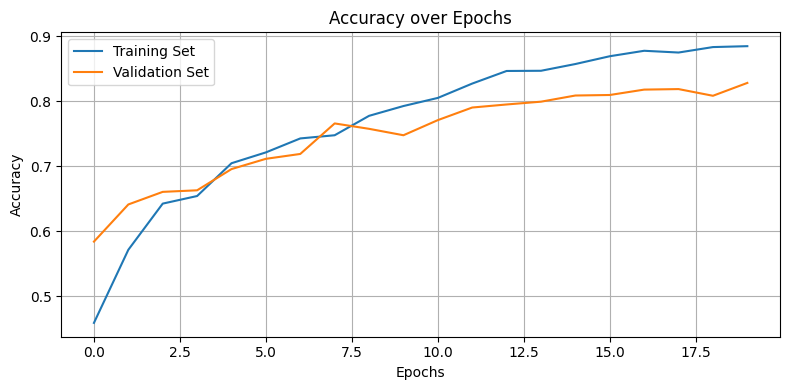

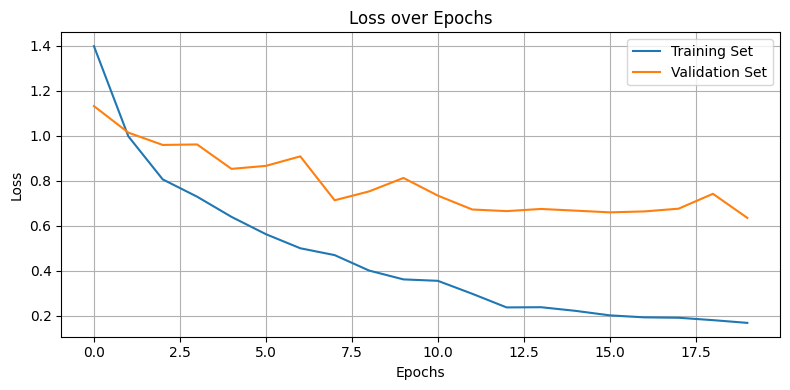

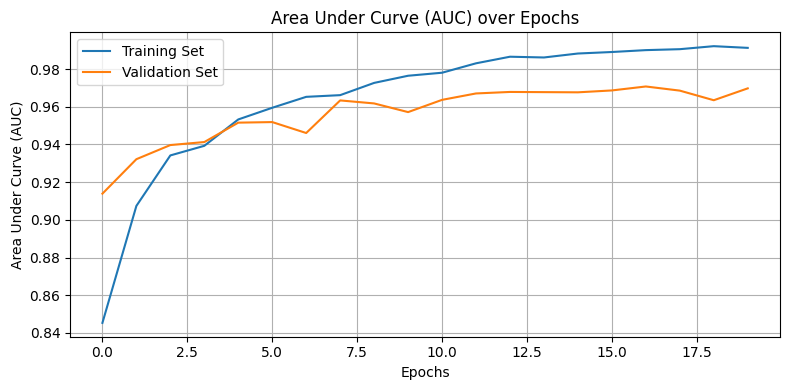

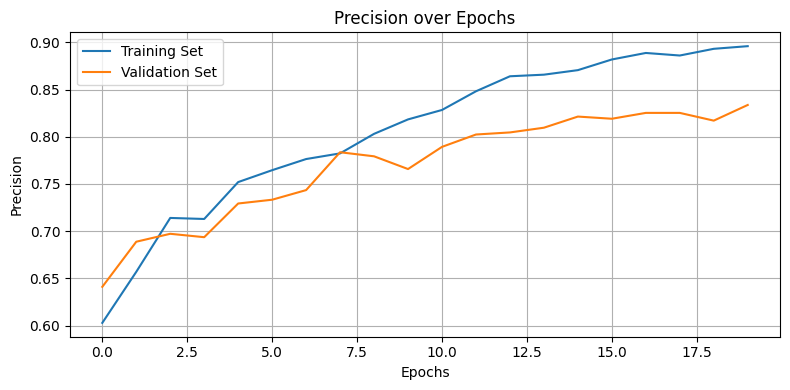

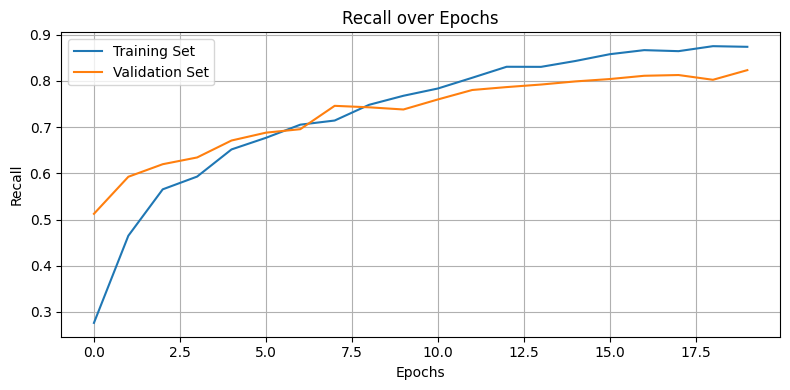

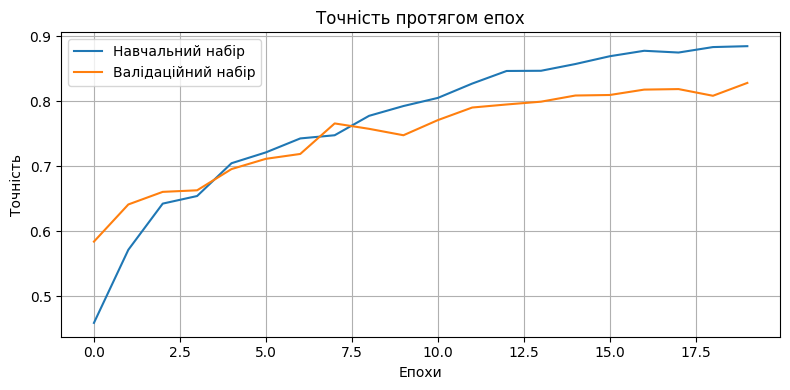

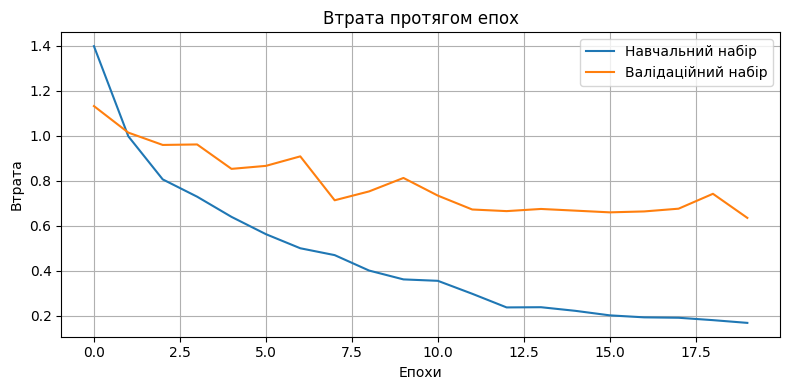

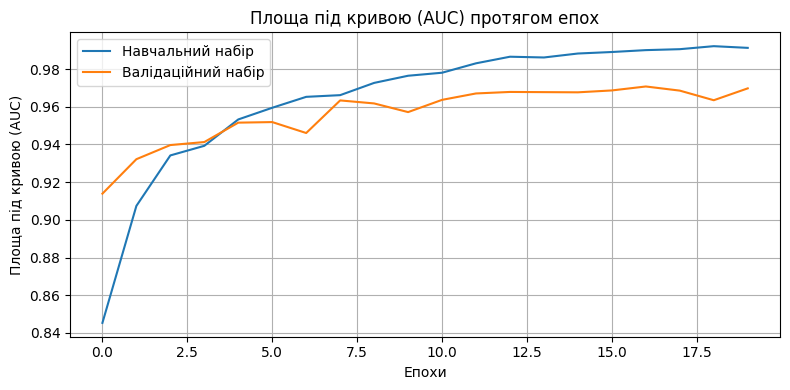

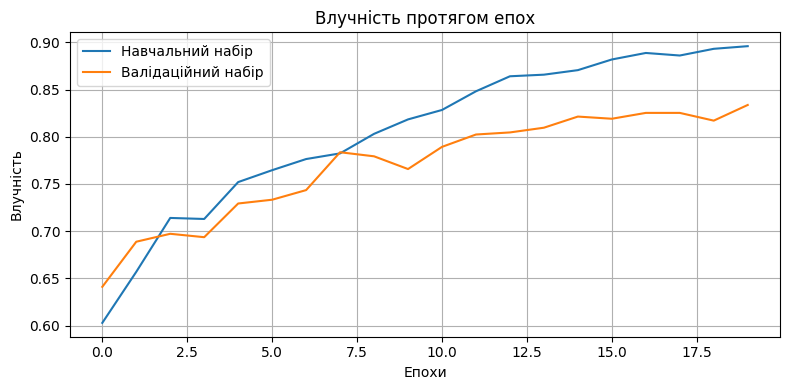

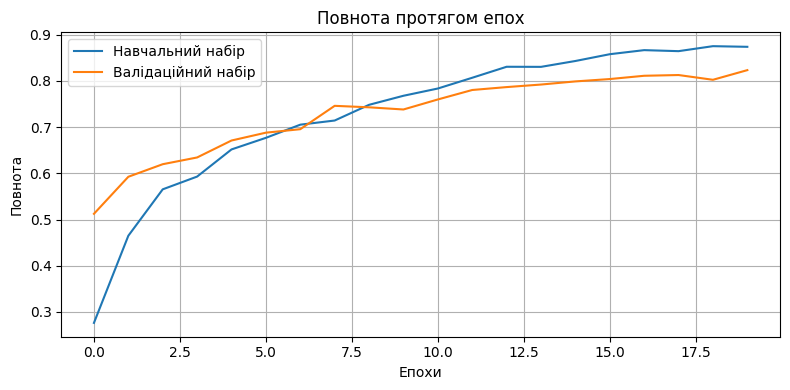

#####  train  #####
201/634 ━━━━━━━━━━━━━━━━━━━━ 7:28 1s/step - accuracy: 0.5830 - auc: 0.8837 - loss: 1.7740 - precision: 0.5946 - recall: 0.5680

KeyboardInterrupt: 

In [40]:
test_model(model, history)

In [ ]:
import cv2
SEGM_DIR = 
def load_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.keras.applications.efficientnet.preprocess_input(img)
    return img, label

def create_mask_from_polygon(polygon, height, width):
    polygon = np.array(polygon, dtype=np.int32).reshape((-1, 2))
    mask = np.zeros((height, width), dtype=np.uint8)
    cv2.fillPoly(mask, [polygon], color=1)
    return mask

def preprocess_and_augment(file_path, label):
    def py_process(path_str):
        import numpy as np
        import cv2
        import os

        path_str = path_str.numpy().decode()
        img = cv2.imread(path_str)
        h, w = img.shape[:2]

        # Build segmentation path
        segm_path = os.path.join(SEGM_DIR, os.path.basename(path_str))

        # If segmentation file does not exist, return original image
        if not os.path.exists(segm_path):
            return img.astype(np.uint8)

        # Read segmentation and parse polygon
        with open(segm_path, 'r') as f:
            parts = list(map(float, f.read().strip().split()))
        coords = np.array(parts[1:], dtype=np.int32).reshape(-1, 2)

        # Create mask and apply it
        mask = np.zeros((h, w), dtype=np.uint8)
        cv2.fillPoly(mask, [coords], 1)
        mask = np.stack([mask]*3, axis=-1)
        masked = img * mask
        return masked.astype(np.uint8)

    # Apply the Python function
    img_masked = tf.py_function(py_process, [file_path], tf.uint8)
    img_masked.set_shape([None, None, 3])

    # Resize and preprocess
    img_masked = tf.image.resize(img_masked, IMG_SIZE)
    img_masked = tf.keras.applications.efficientnet.preprocess_input(img_masked)

    # Augmentation
    img_masked = tf.image.random_flip_left_right(img_masked)
    img_masked = tf.image.random_flip_up_down(img_masked)
    img_masked = tf.image.random_brightness(img_masked, max_delta=0.2)
    img_masked = tf.image.random_contrast(img_masked, lower=0.8, upper=1.2)

    return img_masked, label



train_dataset = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_dataset = train_dataset.map(preprocess_and_augment).shuffle(512).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_dataset = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_dataset = val_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_dataset = test_dataset.map(load_image).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
